Data gambar

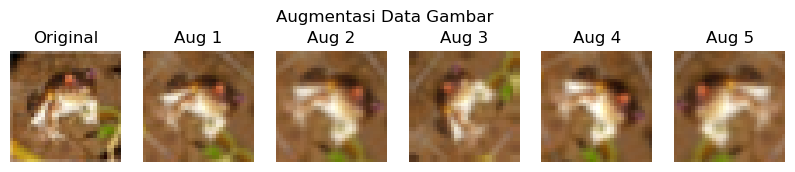

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10

(x_train, _), _ = cifar10.load_data()
img = x_train[0]
img_tf = tf.expand_dims(img, 0)

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomContrast(0.2),
])

plt.figure(figsize=(10,2))
plt.subplot(1,6,1); plt.imshow(img); plt.title('Original'); plt.axis('off')
for i in range(2,7):
    aug_img = data_augmentation(img_tf)
    plt.subplot(1,6,i)
    plt.imshow(aug_img[0].numpy().astype('uint8'))
    plt.title(f'Aug {i-1}'); plt.axis('off')
plt.suptitle('Augmentasi Data Gambar')
plt.show()


Data teks

In [2]:
import nlpaug.augmenter.word as naw

text = "Data augmentation helps deep learning models generalize better."
aug = naw.SynonymAug(aug_src='wordnet')
augmented_text = aug.augment(text)
print("Original :", text)
print("Augmented:", augmented_text)


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /Users/suniantara/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


LookupError: 
**********************************************************************
  Resource [93maveraged_perceptron_tagger_eng[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('averaged_perceptron_tagger_eng')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mtaggers/averaged_perceptron_tagger_eng/[0m

  Searched in:
    - '/Users/suniantara/nltk_data'
    - '/opt/anaconda3/nltk_data'
    - '/opt/anaconda3/share/nltk_data'
    - '/opt/anaconda3/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [ ]:
import random

def random_deletion(text, p=0.2):
    words = text.split()
    if len(words) == 1: return text
    new_words = [word for word in words if random.uniform(0,1) > p]
    if not new_words: return random.choice(words)
    return ' '.join(new_words)

text = "Data augmentation helps deep learning models generalize better."
print("Random deletion:", random_deletion(text))


Data audio

In [ ]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

audio, sr = librosa.load(librosa.example('trumpet'), duration=3)

# Add noise
noise = np.random.normal(0, 0.01, audio.shape)
audio_noise = audio + noise

# Time stretch (percepat 20%)
audio_stretch = librosa.effects.time_stretch(audio, rate=1.2)

# Pitch shift (naik 2 semitone)
audio_pitch = librosa.effects.pitch_shift(audio, sr=sr, n_steps=2)

plt.figure(figsize=(12,3))
plt.subplot(1,4,1); plt.plot(audio); plt.title('Original')
plt.subplot(1,4,2); plt.plot(audio_noise); plt.title('Noise')
plt.subplot(1,4,3); plt.plot(audio_stretch); plt.title('Time Stretch')
plt.subplot(1,4,4); plt.plot(audio_pitch); plt.title('Pitch Shift')
plt.tight_layout(); plt.show()


Data tabular

In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.datasets import make_classification
import pandas as pd

X, y = make_classification(n_samples=200, n_features=3, n_classes=2,
                           weights=[0.9, 0.1], random_state=42)
print("Sebelum SMOTE:", pd.Series(y).value_counts().to_dict())

sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X, y)
print("Setelah SMOTE:", pd.Series(y_res).value_counts().to_dict())